# Digital Image Processing Lab — Lab Task #03
## Image Enhancement and Intensity Transformations

**University:** The University of Azad Jammu and Kashmir  
**Department:** Software Engineering  
**Semester:** Fifth | **Session:** 2024–28 (SE)  
**Lab Instructor:** Engr. Fahad Nisar  

**Student Name:** `Syed Muhammad Hassan Gillani  
**Roll Number:** `2024-SE-42
**Assigned:** November 02, 2026 | **Due:** November 09, 2026, 11:59 PM

---

### Objective
Calculate, implement, and compare grayscale intensity transformations, histogram enhancement, and thresholding while preventing overflow and interpreting their effects.

### Before running
1. Put your personally selected JPG/PNG image (at least 300 × 300 pixels) in the same folder as this notebook.
2. Set `IMAGE_PATH` in the next section to its filename.
3. Run **all cells from a restarted kernel** and keep outputs visible.
4. Replace the student-detail placeholders above before submission.

**Numeric policy:** Perform arithmetic in a wider type, clip to `[0, 255]` before converting to `uint8`, and truncate fractional outputs unless rounding is explicitly requested.

## 0. Imports and image loading

OpenCV: 5.0.0
NumPy: 2.5.4
Shape: (529, 378)
Dtype: uint8
Minimum: 0
Maximum: 255


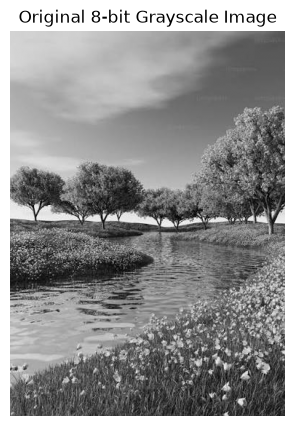

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

# Change this to the filename/path of your personally selected image.
IMAGE_PATH = "your_image.jpg"

image_path = Path(IMAGE_PATH)
if not image_path.is_file():
    raise FileNotFoundError(
        f"Image not found: {image_path.resolve()}\n"
        "Place a JPG/PNG image beside this notebook and update IMAGE_PATH."
    )

original = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
if original is None:
    raise ValueError("OpenCV could not read the image. Check the file format/path.")

if original.dtype != np.uint8:
    raise TypeError(f"Expected an 8-bit grayscale image; got {original.dtype}.")
if original.ndim != 2:
    raise ValueError(f"Expected a 2-D grayscale image; got shape {original.shape}.")
if original.shape[0] < 300 or original.shape[1] < 300:
    raise ValueError(f"Image must be at least 300 x 300 pixels; got {original.shape}.")

print("Shape:", original.shape)
print("Dtype:", original.dtype)
print("Minimum:", int(original.min()))
print("Maximum:", int(original.max()))

plt.figure(figsize=(7, 5))
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original 8-bit Grayscale Image")
plt.axis("off")
plt.show()

# Keep original unchanged; all operations below create separate arrays.
original_copy = original.copy()
assert np.array_equal(original, original_copy)

## Dry-run helper

The supplied pixel lists are small examples for hand calculations. The code below computes raw values, clips where required, and verifies final outputs.

In [2]:
def clip_truncate(values):
    """Clip numeric values to [0,255], then truncate toward zero to uint8."""
    return np.clip(values, 0, 255).astype(np.uint8)

sample = np.array([30, 80, 128, 180, 240], dtype=np.int32)
print("Brightness/contrast sample:", sample)

Brightness/contrast sample: [ 30  80 128 180 240]


## 1. Brightness adjustment (β = +40 and −40)

Brightness adds or subtracts a constant from every pixel. This shifts intensity values; it does not directly multiply the differences between pixels.

### Dry run 1

For pixels `[30, 80, 128, 180, 240]`:
- For β = +40, raw values are `r + 40`; values above 255 are clipped.
- For β = −40, raw values are `r − 40`; values below 0 are clipped.
- Clipping can merge distinct values at 0 or 255, losing detail in those regions.

In [3]:
for beta in (40, -40):
    raw = sample.astype(np.int32) + beta
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    print(f"β = {beta}")
    print("  Raw:     ", raw.tolist())
    print("  Clipped: ", clipped.tolist())
    print("  uint8:   ", final.tolist())

β = 40
  Raw:      [70, 120, 168, 220, 280]
  Clipped:  [70, 120, 168, 220, 255]
  uint8:    [70, 120, 168, 220, 255]
β = -40
  Raw:      [-10, 40, 88, 140, 200]
  Clipped:  [0, 40, 88, 140, 200]
  uint8:    [0, 40, 88, 140, 200]


### Image implementation and comparison

Nested-loop result matches NumPy: True


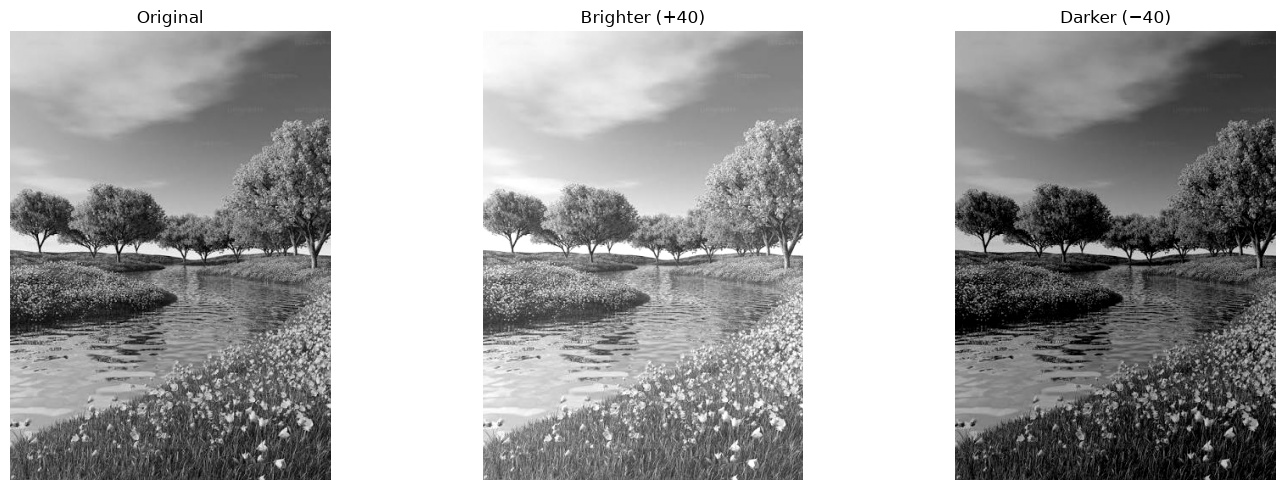

In [4]:
bright_raw = original.astype(np.int16) + 40
dark_raw = original.astype(np.int16) - 40
brighter = clip_truncate(bright_raw)
darker = clip_truncate(dark_raw)

# Required nested-loop implementation for +40.
bright_loop = np.empty_like(original)
for y in range(original.shape[0]):
    for x in range(original.shape[1]):
        value = int(original[y, x]) + 40
        bright_loop[y, x] = min(255, max(0, value))

print("Nested-loop result matches NumPy:", np.array_equal(brighter, bright_loop))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [original, brighter, darker],
                          ["Original", "Brighter (+40)", "Darker (−40)"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Observation:** Adding 40 brightens the image and subtracting 40 darkens it. Values pushed beyond the valid 8-bit range saturate at 255 or 0, so intensity distinctions can be lost. The nested-loop output should exactly match the vectorized NumPy result.

## 2. Linear contrast from zero (α = 1.5, β = 0)

The transformation is `s = αr + β`. With α = 1.5 and β = 0, intensities are multiplied by 1.5. This increases distances from zero and can saturate highlights.

### Dry run 2

Calculate `1.5r`, clip to `[0,255]`, and truncate fractional values.

In [5]:
alpha, beta = 1.5, 0
raw = alpha * sample.astype(np.float64) + beta
clipped = np.clip(raw, 0, 255)
final = clipped.astype(np.uint8)  # truncation, not rounding
print("Raw:", raw.tolist())
print("Clipped:", clipped.tolist())
print("Final uint8:", final.tolist())
print("Saturated input pixels (raw >= 255):", sample[raw >= 255].tolist())

Raw: [45.0, 120.0, 192.0, 270.0, 360.0]
Clipped: [45.0, 120.0, 192.0, 255.0, 255.0]
Final uint8: [45, 120, 192, 255, 255]
Saturated input pixels (raw >= 255): [180, 240]


### Image implementation and comparison

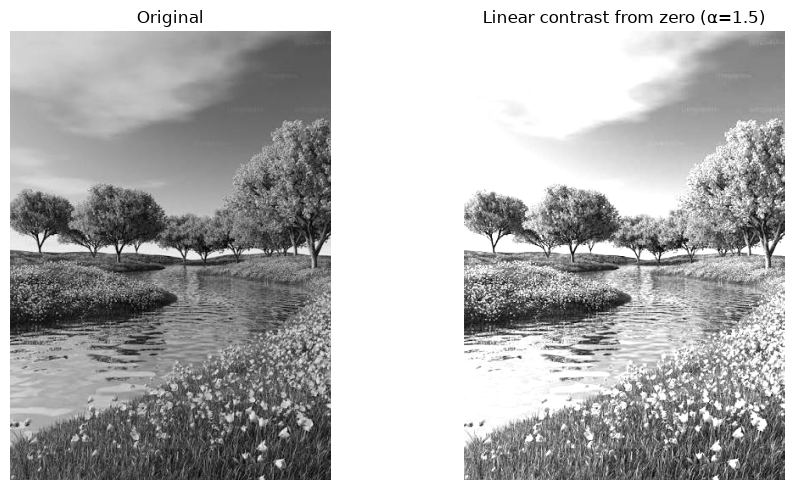

Original mean: 124.95269101129215
Transformed mean: 179.59600324061572
Pixels clipped to 255: 50806


In [6]:
linear_zero_raw = 1.5 * original.astype(np.float32)
linear_zero = clip_truncate(linear_zero_raw)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [original, linear_zero],
                          ["Original", "Linear contrast from zero (α=1.5)"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("Original mean:", float(original.mean()))
print("Transformed mean:", float(linear_zero.mean()))
print("Pixels clipped to 255:", int(np.count_nonzero(linear_zero_raw >= 255)))

**Observation:** The mean intensity generally increases, and high input values may become 255. This is contrast expansion about zero, not a brightness-only shift; clipping compresses all sufficiently bright inputs to the same maximum value.

## 3. Contrast centered at 128 (α = 1.5 and 0.5)

Use `s = (r − 128)α + 128`. The midpoint 128 remains fixed. α = 1.5 expands distances from 128; α = 0.5 reduces them.

### Dry run 3

Show the intermediate difference `(r − 128)`, multiplication by α, addition of 128, clipping, and final truncation. At `r = 128`, the difference is zero, so the output remains 128 for either α.

In [7]:
centered_sample = sample.astype(np.float64) - 128
for a in (1.5, 0.5):
    multiplied = centered_sample * a
    raw = multiplied + 128
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    print(f"α = {a}")
    print("  r − 128:", centered_sample.tolist())
    print("  multiplied:", multiplied.tolist())
    print("  + 128 (raw):", raw.tolist())
    print("  clipped:", clipped.tolist())
    print("  uint8:", final.tolist())

α = 1.5
  r − 128: [-98.0, -48.0, 0.0, 52.0, 112.0]
  multiplied: [-147.0, -72.0, 0.0, 78.0, 168.0]
  + 128 (raw): [-19.0, 56.0, 128.0, 206.0, 296.0]
  clipped: [0.0, 56.0, 128.0, 206.0, 255.0]
  uint8: [0, 56, 128, 206, 255]
α = 0.5
  r − 128: [-98.0, -48.0, 0.0, 52.0, 112.0]
  multiplied: [-49.0, -24.0, 0.0, 26.0, 56.0]
  + 128 (raw): [79.0, 104.0, 128.0, 154.0, 184.0]
  clipped: [79.0, 104.0, 128.0, 154.0, 184.0]
  uint8: [79, 104, 128, 154, 184]


### Image implementation and comparison

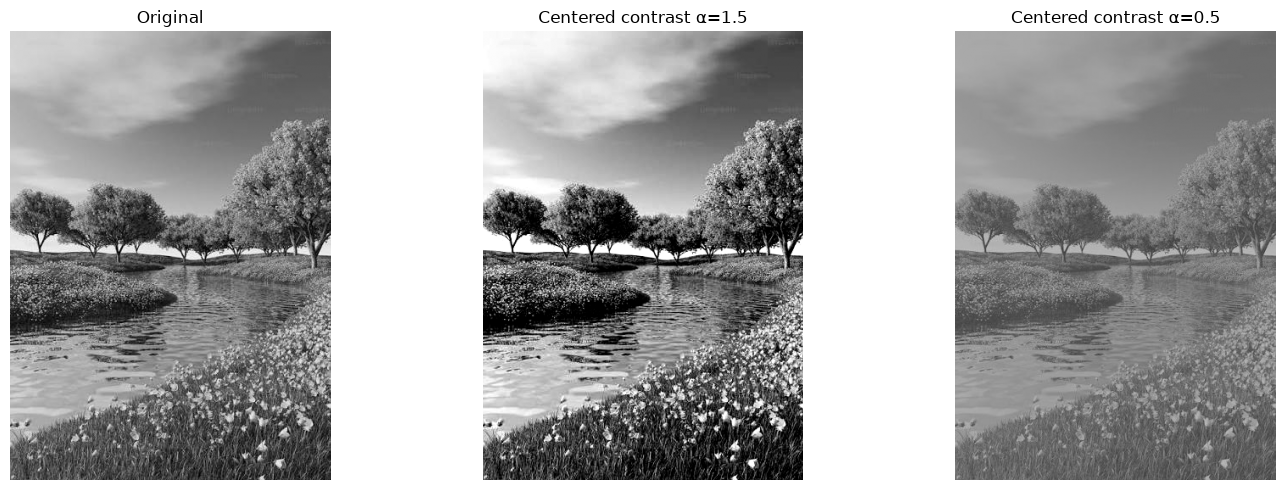

In [8]:
def contrast_about_128(img, alpha):
    raw = (img.astype(np.float32) - 128.0) * alpha + 128.0
    return clip_truncate(raw)

centered_15 = contrast_about_128(original, 1.5)
centered_05 = contrast_about_128(original, 0.5)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [original, centered_15, centered_05],
                          ["Original", "Centered contrast α=1.5", "Centered contrast α=0.5"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Observation:** α = 1.5 increases contrast around mid-gray and may clip dark and bright extremes. α = 0.5 moves values toward 128, reducing contrast. Unlike contrast from zero, the centered transform preserves 128 as its pivot.

## 4. Image negative

The negative transformation is `s = 255 − r`. It reverses the grayscale scale: dark pixels become bright and bright pixels become dark. It can help inspect features that are difficult to see against their original background, such as light structures on a dark background.

### Dry run 4

Apply the negative twice and verify that the original pixels are recovered.

In [9]:
negative_sample = 255 - sample
double_negative = 255 - negative_sample
print("Original:", sample.tolist())
print("Negative:", negative_sample.tolist())
print("Negative applied again:", double_negative.tolist())
print("Recovered original:", np.array_equal(sample, double_negative))

Original: [30, 80, 128, 180, 240]
Negative: [225, 175, 127, 75, 15]
Negative applied again: [30, 80, 128, 180, 240]
Recovered original: True


### Image implementation

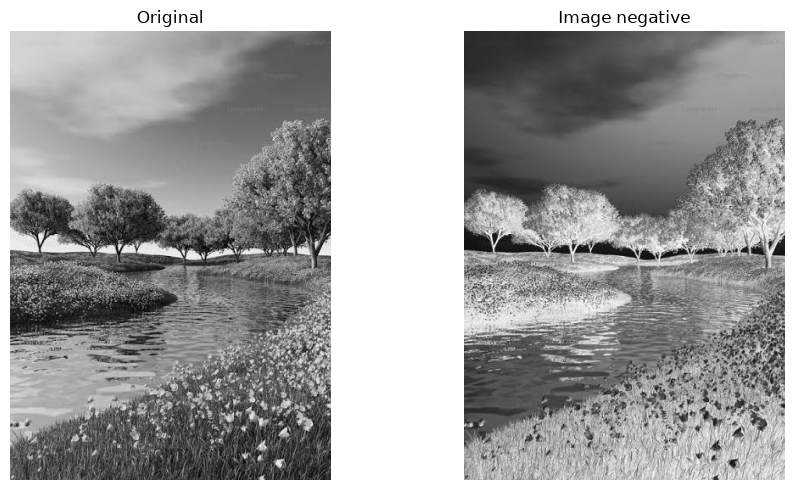

In [10]:
negative = 255 - original
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [original, negative], ["Original", "Image negative"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Observation:** The negative reverses intensity ordering while retaining spatial structure. Applying it twice returns the original image exactly.

## 5. Gamma correction (γ = 0.5 and 2.0)

Use `s = 255(r/255)^γ`. Normalize first, apply the power, then scale by 255. With this convention, γ < 1 brightens darker regions, while γ > 1 darkens them. The endpoints 0 and 255 remain fixed.

### Dry run 5

Use pixels `[0, 64, 128, 192, 255]`. Keep full precision through normalization, power, and scaling; truncate only the final result. Small differences from rounded slide examples can occur because this task truncates rather than rounds.

In [11]:
gamma_sample = np.array([0, 64, 128, 192, 255], dtype=np.float64)
normalized = gamma_sample / 255.0
for gamma in (0.5, 2.0):
    powered = normalized ** gamma
    scaled = 255.0 * powered
    final = np.clip(scaled, 0, 255).astype(np.uint8)
    print(f"γ = {gamma}")
    print("  Normalized:", normalized.tolist())
    print("  Power:", powered.tolist())
    print("  Scaled:", scaled.tolist())
    print("  Truncated uint8:", final.tolist())

γ = 0.5
  Normalized: [0.0, 0.25098039215686274, 0.5019607843137255, 0.7529411764705882, 1.0]
  Power: [0.0, 0.5009794328681196, 0.7084919084320762, 0.8677218312746247, 1.0]
  Scaled: [0.0, 127.7497553813705, 180.66543665017943, 221.2690669750293, 255.0]
  Truncated uint8: [0, 127, 180, 221, 255]
γ = 2.0
  Normalized: [0.0, 0.25098039215686274, 0.5019607843137255, 0.7529411764705882, 1.0]
  Power: [0.0, 0.0629911572472126, 0.2519646289888504, 0.5669204152249134, 1.0]
  Scaled: [0.0, 16.062745098039215, 64.25098039215686, 144.56470588235294, 255.0]
  Truncated uint8: [0, 16, 64, 144, 255]


### Image implementation and comparison

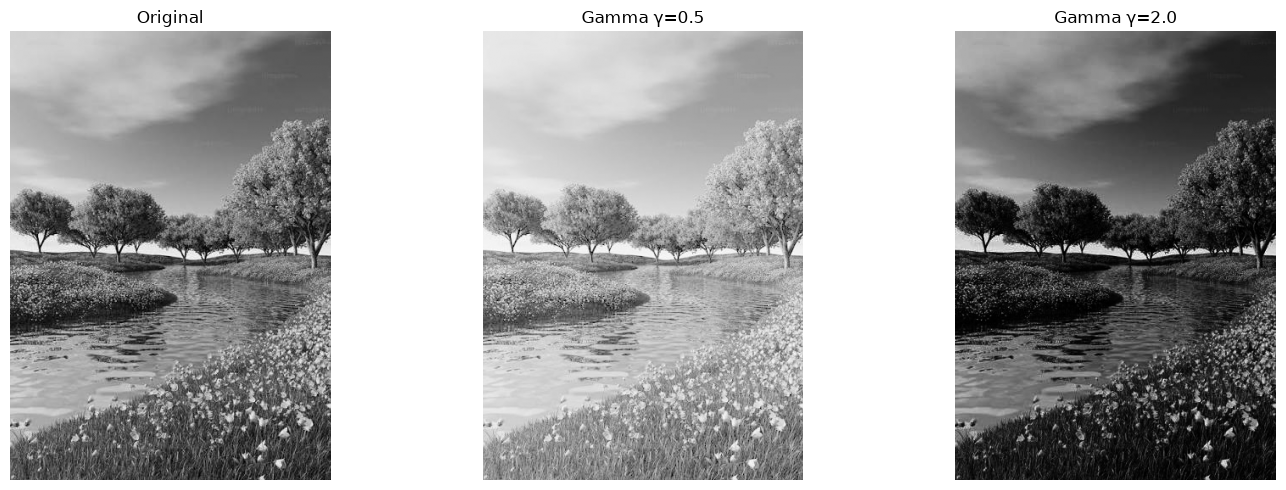

γ=0.5 endpoints: 0 255
γ=2.0 endpoints: 0 255


In [12]:
def gamma_correct(img, gamma):
    normalized = img.astype(np.float32) / 255.0
    scaled = 255.0 * np.power(normalized, gamma)
    return clip_truncate(scaled)

gamma_05 = gamma_correct(original, 0.5)
gamma_20 = gamma_correct(original, 2.0)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [original, gamma_05, gamma_20],
                          ["Original", "Gamma γ=0.5", "Gamma γ=2.0"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("γ=0.5 endpoints:", int(gamma_05.min()), int(gamma_05.max()))
print("γ=2.0 endpoints:", int(gamma_20.min()), int(gamma_20.max()))

**Observation:** γ = 0.5 lifts darker intensities and reveals dark-region detail; γ = 2.0 suppresses darker intensities. Both preserve exact endpoint values 0 and 255. The stated gamma convention is important: some references define the exponent inversely.

## 6. Grayscale histogram

A grayscale histogram counts how many pixels occur at each intensity. Plot 256 bins over the intensity range 0–256.

### Dry run 6

For `A = [[0, 50, 50, 100], [100, 150, 200, 255]]`, find nonzero frequencies, probabilities, and total count. A histogram discards spatial coordinates, so different image arrangements can have the same histogram.

In [13]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
values, counts = np.unique(A, return_counts=True)
total = A.size
print("Total pixel count:", total)
print("Intensity | Frequency | Probability")
for value, count in zip(values, counts):
    print(f"{int(value):9d} | {int(count):9d} | {count/total:.4f}")

Total pixel count: 8
Intensity | Frequency | Probability
        0 |         1 | 0.1250
       50 |         2 | 0.2500
      100 |         2 | 0.2500
      150 |         1 | 0.1250
      200 |         1 | 0.1250
      255 |         1 | 0.1250


### Image histogram

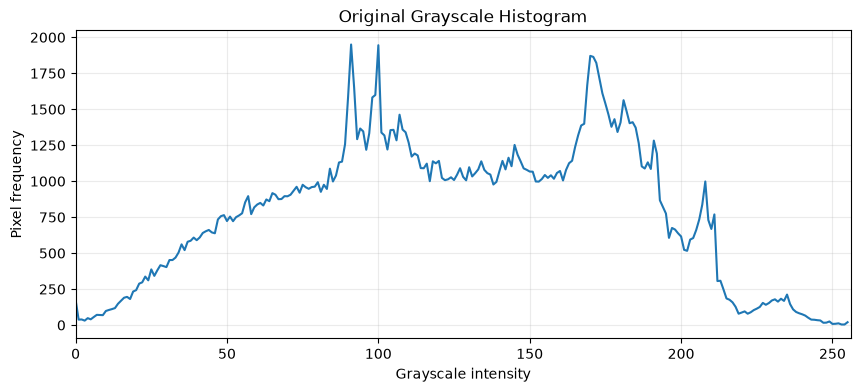

Most frequent intensity: 91 (1950 pixels)
Intensity range present: 0 to 255


In [14]:
hist = cv2.calcHist([original], [0], None, [256], [0, 256]).ravel()
plt.figure(figsize=(10, 4))
plt.plot(np.arange(256), hist)
plt.xlim(0, 256); plt.xlabel("Grayscale intensity")
plt.ylabel("Pixel frequency"); plt.title("Original Grayscale Histogram")
plt.grid(alpha=0.25); plt.show()

peak = int(np.argmax(hist))
print(f"Most frequent intensity: {peak} ({int(hist[peak])} pixels)")
print(f"Intensity range present: {int(original.min())} to {int(original.max())}")

**Interpretation (write two image-specific sentences after viewing the plot):**  
1. The histogram shows where the image's pixel intensities are concentrated (for example, toward dark, middle, or bright values).  
2. It does not show where those pixels occur in the image, because spatial positions are not represented.

## 7. Global histogram equalization

`cv2.equalizeHist` redistributes grayscale values using the cumulative distribution function (CDF). It is a global operation: one mapping is applied across the full image.

### Dry run 7

For `[50, 50, 100, 150]`, calculate frequencies, cumulative counts, and CDF. Then calculate:
- `255 × CDF`
- `255 × (CDF − CDFmin)/(1 − CDFmin)`

Here `CDFmin` is the lowest nonzero CDF. Round to the nearest integer with .5 rounded upward. The second mapping is the common minimum-CDF normalization; OpenCV's discrete implementation may differ in edge cases due to its histogram/LUT handling.

In [15]:
eq_sample = np.array([50, 50, 100, 150], dtype=np.uint8)
levels, freqs = np.unique(eq_sample, return_counts=True)
cum_counts = np.cumsum(freqs)
cdf = cum_counts / eq_sample.size
cdf_min = cdf[0]

def round_half_up_nonnegative(x):
    return np.floor(np.asarray(x) + 0.5).astype(int)

map_cdf = round_half_up_nonnegative(255 * cdf)
map_min = round_half_up_nonnegative(255 * (cdf - cdf_min) / (1 - cdf_min))

print("Intensity | Frequency | Cumulative count | CDF | 255*CDF | Min-CDF map")
for row in zip(levels, freqs, cum_counts, cdf, map_cdf, map_min):
    print(f"{int(row[0]):9d} | {int(row[1]):9d} | {int(row[2]):16d} | "
          f"{row[3]:.4f} | {int(row[4]):7d} | {int(row[5]):11d}")
print("Output using 255*CDF:", [int(map_cdf[np.where(levels == p)[0][0]]) for p in eq_sample])
print("Output using min-CDF:", [int(map_min[np.where(levels == p)[0][0]]) for p in eq_sample])

Intensity | Frequency | Cumulative count | CDF | 255*CDF | Min-CDF map
       50 |         2 |                2 | 0.5000 |     128 |           0
      100 |         1 |                3 | 0.7500 |     191 |         128
      150 |         1 |                4 | 1.0000 |     255 |         255
Output using 255*CDF: [128, 128, 191, 255]
Output using min-CDF: [0, 0, 128, 255]


### Image equalization and histograms

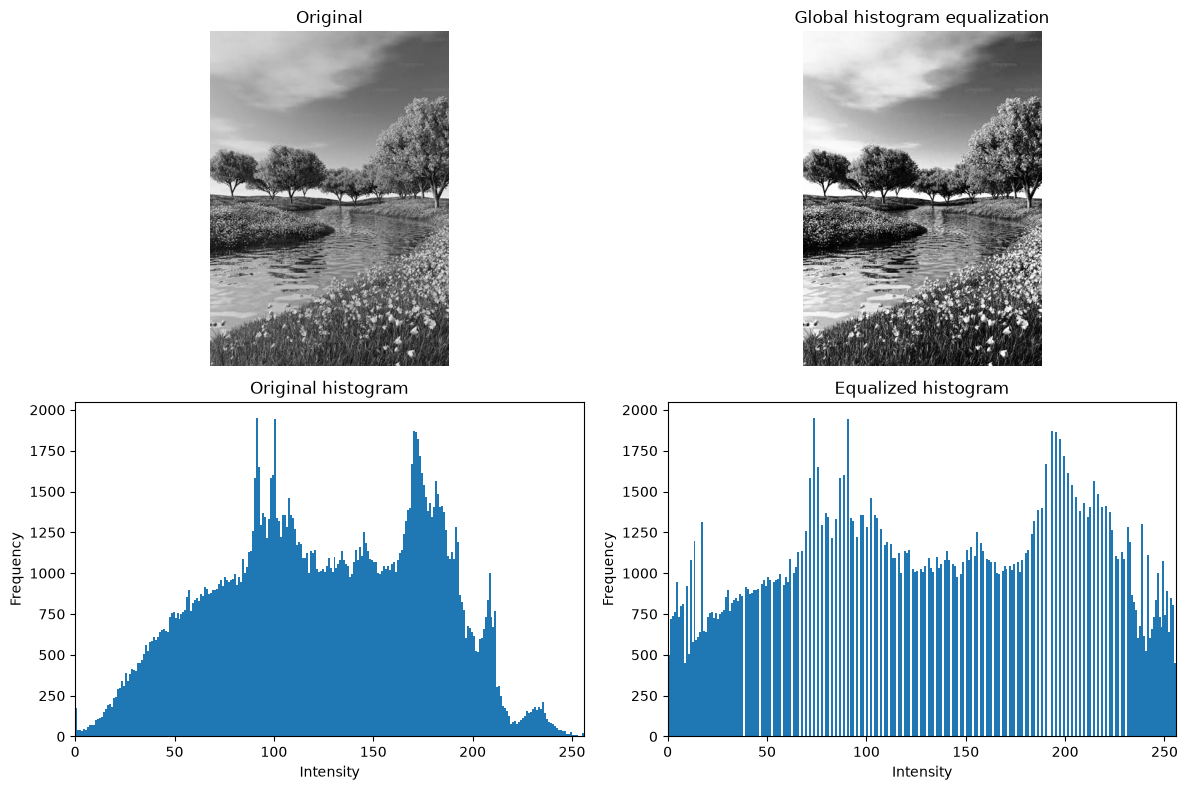

In [16]:
equalized = cv2.equalizeHist(original)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Global histogram equalization")
axes[1, 0].hist(original.ravel(), bins=256, range=(0, 256))
axes[1, 0].set_title("Original histogram")
axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("Equalized histogram")
for ax in axes.flat: 
    if ax in axes[0]: ax.axis("off")
    else: ax.set_xlim(0, 256); ax.set_xlabel("Intensity"); ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show()

**Observation:** Global equalization can improve overall contrast when the original intensities occupy a limited range. It may also make noise more visible, and it may not handle strongly uneven illumination well because the same global mapping is used everywhere.

## 8. CLAHE (clipLimit = 2.0, tileGridSize = (8, 8))

Contrast Limited Adaptive Histogram Equalization (CLAHE) enhances local regions. `tileGridSize=(8,8)` specifies **8 tiles across and 8 tiles down**, not 8 pixels per tile. Contrast limiting helps reduce excessive amplification.

### Dry run 8

Use four-bin histogram `[6, 2, 0, 0]` and absolute cap 4. Clip counts, redistribute total excess equally across four bins (fractions allowed), then calculate the new CDF. This simplified model is not OpenCV's integer redistribution, and the absolute cap is not the `clipLimit` parameter.

In [17]:
four_bin = np.array([6.0, 2.0, 0.0, 0.0])
cap = 4.0
clipped_counts = np.minimum(four_bin, cap)
excess = float(np.sum(four_bin - clipped_counts))
redistributed = clipped_counts + excess / len(four_bin)
new_cdf = np.cumsum(redistributed) / np.sum(redistributed)
print("Original histogram:", four_bin.tolist())
print("After clipping:", clipped_counts.tolist())
print("Excess:", excess)
print("Redistributed excess per bin:", excess / len(four_bin))
print("New histogram:", redistributed.tolist())
print("New CDF:", new_cdf.tolist())

Original histogram: [6.0, 2.0, 0.0, 0.0]
After clipping: [4.0, 2.0, 0.0, 0.0]
Excess: 2.0
Redistributed excess per bin: 0.5
New histogram: [4.5, 2.5, 0.5, 0.5]
New CDF: [0.5625, 0.875, 0.9375, 1.0]


**Why interpolate neighboring tile mappings?** A pixel near a tile boundary is influenced by adjacent tiles. Interpolating their mappings avoids abrupt visible transitions or block boundaries between neighboring regions.

### Image CLAHE implementation and comparison

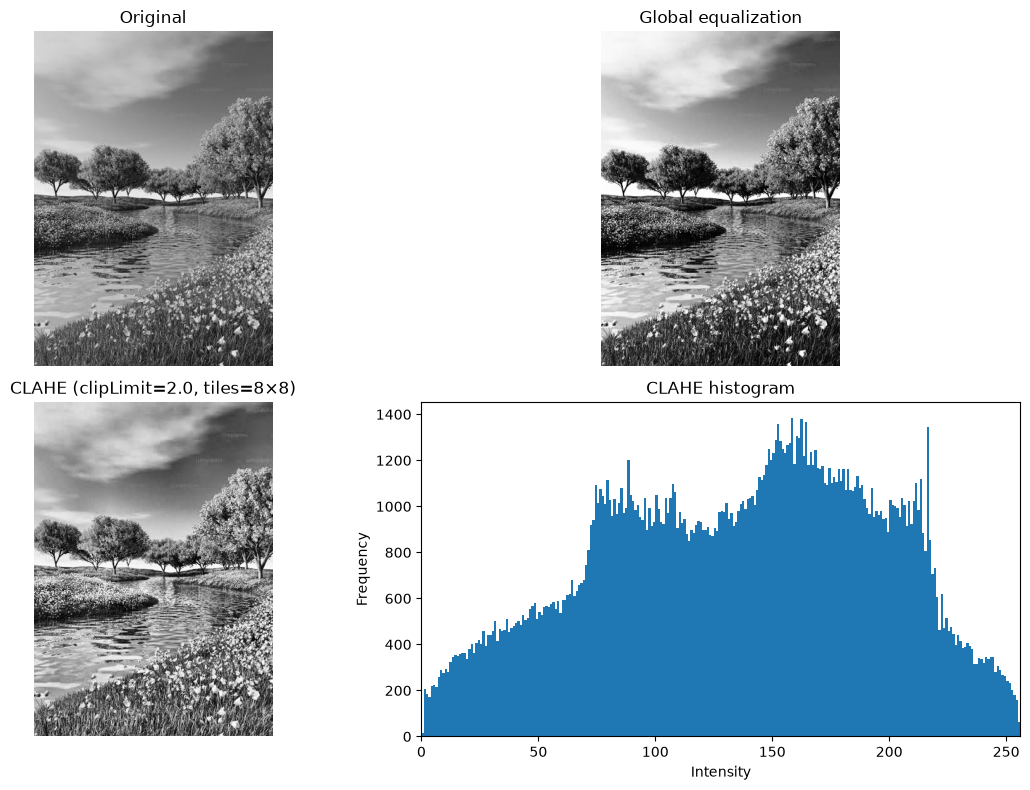

In [18]:
clahe_operator = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_image = clahe_operator.apply(original)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Global equalization")
axes[1, 0].imshow(clahe_image, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("CLAHE (clipLimit=2.0, tiles=8×8)")
axes[1, 1].hist(clahe_image.ravel(), bins=256, range=(0, 256))
axes[1, 1].set_title("CLAHE histogram")
for ax in [axes[0,0], axes[0,1], axes[1,0]]: ax.axis("off")
axes[1,1].set_xlim(0,256); axes[1,1].set_xlabel("Intensity"); axes[1,1].set_ylabel("Frequency")
plt.tight_layout(); plt.show()

**Observation:** CLAHE is often more useful than global equalization when lighting varies across the image because it adapts contrast locally. Compare the displayed regions: local enhancement can reveal detail in one area without forcing a single mapping on the whole image, although noise may also be amplified.

## 9. Fixed binary thresholding (T = 127)

For binary thresholding, a pixel is white (255) when `r > T`; otherwise it is black (0).

### Dry run 9

Apply thresholds 127 and 180 to `[0, 80, 127, 128, 180, 255]`. Count white pixels for each threshold.

In [19]:
threshold_sample = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
for T in (127, 180):
    result = np.where(threshold_sample > T, 255, 0).astype(np.uint8)
    print(f"T={T}: {result.tolist()} | white-pixel count={int(np.count_nonzero(result == 255))}")

T=127: [0, 0, 0, 255, 255, 255] | white-pixel count=3
T=180: [0, 0, 0, 0, 0, 255] | white-pixel count=1


### Image implementation

Unique values in fixed-threshold image: [0, 255]


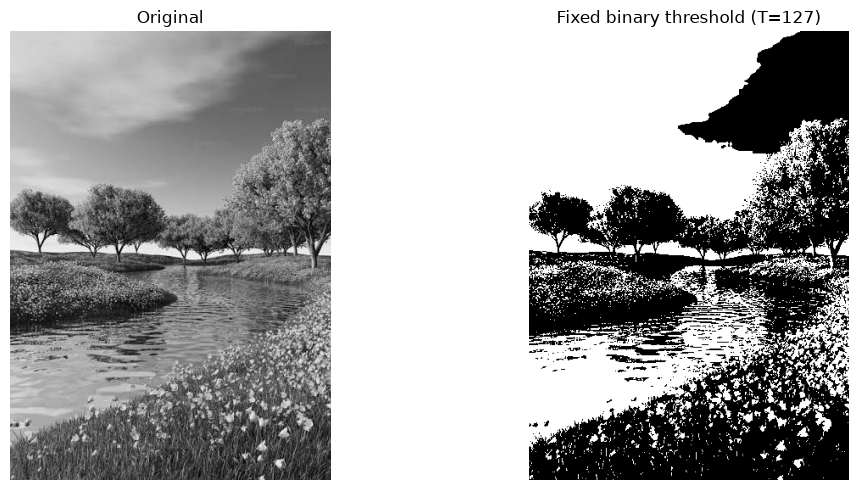

In [20]:
fixed_T = 127
_, fixed_mask = cv2.threshold(original, fixed_T, 255, cv2.THRESH_BINARY)
print("Unique values in fixed-threshold image:", np.unique(fixed_mask).tolist())
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(fixed_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed binary threshold (T=127)"); plt.axis("off")
plt.tight_layout(); plt.show()

**Observation:** Fixed thresholding is simple and effective when foreground and background intensities are reasonably separated and illumination is consistent. The output contains only 0 and 255.

## 10. Otsu thresholding

Otsu's method selects a global threshold by maximizing between-class variance. For each candidate threshold, pixels are split into classes `r ≤ T` and `r > T`.

### Dry run 10

Use `[0, 1, 4, 5]` without rescaling. Test T = 0, 1, 2, 3, 4. Calculate class weights, class means, and `w0*w1*(μ0−μ1)^2`. Choose the smallest T among tied maxima.

In [21]:
otsu_sample = np.array([0, 1, 4, 5], dtype=np.float64)
scores = []
for T in range(5):
    c0 = otsu_sample[otsu_sample <= T]
    c1 = otsu_sample[otsu_sample > T]
    w0, w1 = len(c0)/len(otsu_sample), len(c1)/len(otsu_sample)
    mu0 = float(c0.mean()) if len(c0) else float("nan")
    mu1 = float(c1.mean()) if len(c1) else float("nan")
    score = w0*w1*(mu0-mu1)**2 if len(c0) and len(c1) else 0.0
    scores.append(score)
    print(f"T={T}: class0={c0.tolist()}, class1={c1.tolist()}, "
          f"w0={w0:.2f}, w1={w1:.2f}, μ0={mu0}, μ1={mu1}, score={score:.4f}")
best_T = min(T for T, score in enumerate(scores) if score == max(scores))
predicted_mask = np.where(otsu_sample > best_T, 255, 0).astype(np.uint8)
print("Smallest maximizing T:", best_T)
print("Predicted mask:", predicted_mask.tolist())

T=0: class0=[0.0], class1=[1.0, 4.0, 5.0], w0=0.25, w1=0.75, μ0=0.0, μ1=3.3333333333333335, score=2.0833
T=1: class0=[0.0, 1.0], class1=[4.0, 5.0], w0=0.50, w1=0.50, μ0=0.5, μ1=4.5, score=4.0000
T=2: class0=[0.0, 1.0], class1=[4.0, 5.0], w0=0.50, w1=0.50, μ0=0.5, μ1=4.5, score=4.0000
T=3: class0=[0.0, 1.0], class1=[4.0, 5.0], w0=0.50, w1=0.50, μ0=0.5, μ1=4.5, score=4.0000
T=4: class0=[0.0, 1.0, 4.0], class1=[5.0], w0=0.75, w1=0.25, μ0=1.6666666666666667, μ1=5.0, score=2.0833
Smallest maximizing T: 1
Predicted mask: [0, 0, 255, 255]


### Verify the dry run and apply Otsu to the image

OpenCV dry-run threshold: 1.0
OpenCV dry-run mask: [0, 0, 255, 255]
Manual predicted mask: [0, 0, 255, 255]
Image Otsu threshold returned by OpenCV: 124.0
Otsu mask unique values: [0, 255]


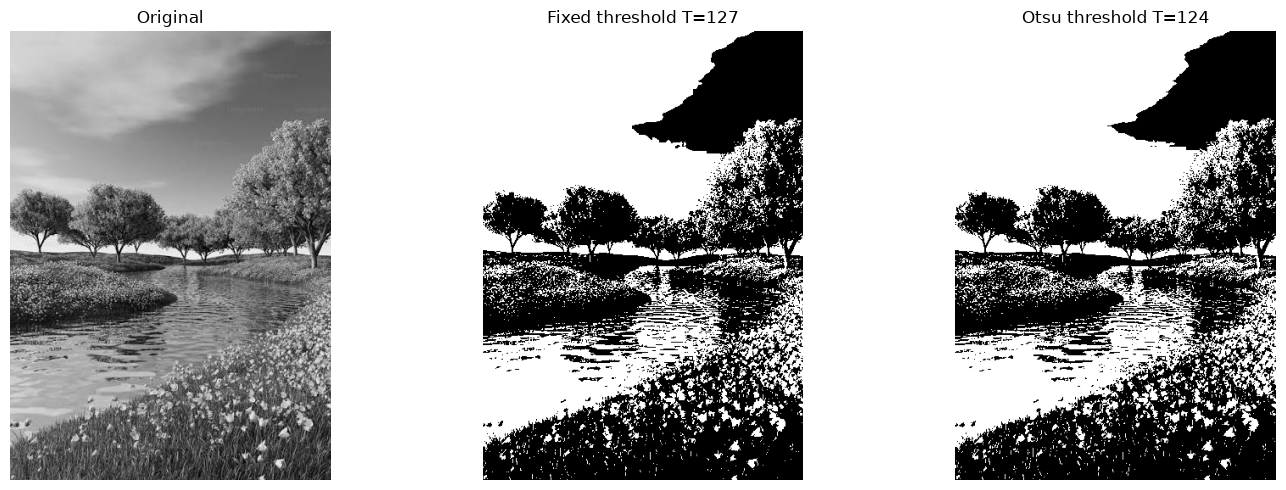

Pixels differing between fixed and Otsu masks: 3143


In [22]:
small_img = otsu_sample.astype(np.uint8).reshape(2, 2)
otsu_small_value, otsu_small_mask = cv2.threshold(
    small_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("OpenCV dry-run threshold:", otsu_small_value)
print("OpenCV dry-run mask:", otsu_small_mask.ravel().tolist())
print("Manual predicted mask:", predicted_mask.tolist())

otsu_threshold, otsu_mask = cv2.threshold(
    original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
print("Image Otsu threshold returned by OpenCV:", otsu_threshold)
print("Otsu mask unique values:", np.unique(otsu_mask).tolist())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [original, fixed_mask, otsu_mask],
                          ["Original", "Fixed threshold T=127", f"Otsu threshold T={otsu_threshold:.0f}"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("Pixels differing between fixed and Otsu masks:", int(np.count_nonzero(fixed_mask != otsu_mask)))

**Observation:** Otsu is useful when the image histogram has separable intensity groups, often foreground and background. It selects one global threshold and may be less effective under uneven illumination.

## 11. Adaptive Gaussian thresholding

Adaptive thresholding computes a local threshold from a neighborhood. This can help when illumination changes across the image. For the image task, use Gaussian weighting, binary output, `blockSize=11`, and `C=2`.

### Dry run 11

Neighborhood:
`[[100,100,100],[100,120,140],[140,140,140]]`

Gaussian weights:
`[[1,2,1],[2,4,2],[1,2,1]] / 16`

Calculate weighted mean and `T = mean − 2`. Classify the center pixel using `r > T`, and also classify a pixel equal to T.

In [23]:
neighborhood = np.array([[100, 100, 100],
                           [100, 120, 140],
                           [140, 140, 140]], dtype=np.float64)
weights = np.array([[1, 2, 1],
                    [2, 4, 2],
                    [1, 2, 1]], dtype=np.float64) / 16.0
weighted_mean = float(np.sum(neighborhood * weights))
local_T = weighted_mean - 2
center_value = neighborhood[1, 1]
center_output = 255 if center_value > local_T else 0
equal_output = 255 if local_T > local_T else 0
print("Weighted mean:", weighted_mean)
print("Local threshold T = mean - 2:", local_T)
print("Center pixel:", center_value, "=>", center_output)
print("Pixel equal to T:", local_T, "=>", equal_output, "(comparison is strictly r > T)")

Weighted mean: 120.0
Local threshold T = mean - 2: 118.0
Center pixel: 120.0 => 255
Pixel equal to T: 118.0 => 0 (comparison is strictly r > T)


### Image implementation and comparison

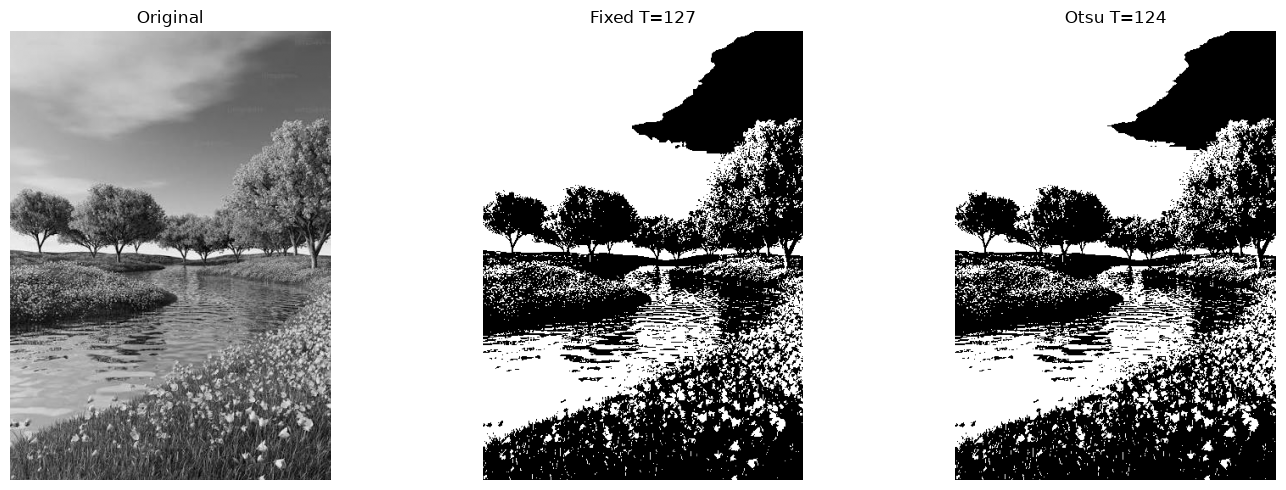

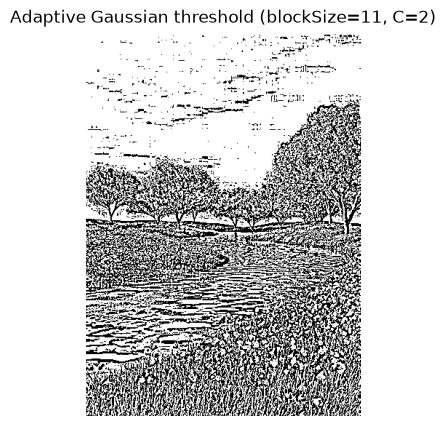

Adaptive mask unique values: [0, 255]
Pixels differing from fixed mask: 56693
Pixels differing from Otsu mask: 55354


In [24]:
adaptive_mask = cv2.adaptiveThreshold(
    original, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [original, fixed_mask, otsu_mask],
                          ["Original", "Fixed T=127", f"Otsu T={otsu_threshold:.0f}"]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(adaptive_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Adaptive Gaussian threshold (blockSize=11, C=2)")
plt.axis("off"); plt.show()
print("Adaptive mask unique values:", np.unique(adaptive_mask).tolist())
print("Pixels differing from fixed mask:", int(np.count_nonzero(adaptive_mask != fixed_mask)))
print("Pixels differing from Otsu mask:", int(np.count_nonzero(adaptive_mask != otsu_mask)))

**Observation:** Adaptive Gaussian thresholding can separate foreground and background when brightness varies spatially, because each pixel is compared with a neighborhood-based threshold. `blockSize=11` means an 11×11 neighborhood, and `C=2` is subtracted from the weighted local mean.

## Overall discussion and conclusions

### Key concepts
- **Clipping:** Restricts values to the valid grayscale range `[0,255]`. Values outside the range saturate at an endpoint, potentially removing distinctions.
- **Overflow:** Arithmetic directly in `uint8` can wrap around because the type cannot represent values outside 0–255. Use wider types (such as `int16` or `float32`) for calculations, then clip and convert.
- **Brightness vs. contrast:** Adding a constant shifts intensities (brightness). Multiplying or scaling around a pivot changes the separation between intensities (contrast).
- **Gamma convention:** In `s = 255(r/255)^γ`, γ below 1 brightens dark regions and γ above 1 darkens them.
- **Global vs. local enhancement:** Global equalization uses one mapping for the whole image. CLAHE works on local tiles and is often preferable for uneven lighting.
- **Global vs. local thresholding:** Fixed and Otsu thresholds use one threshold for the whole image. Adaptive thresholding uses local neighborhoods and can help under nonuniform illumination.